In [1]:
#Project objective

#Project: Network Intrusion Detection and Attack Classification Using Machine Learning

In [2]:
"""
I’ll structure it as a proper ML project:

Problem Definition → Data Collection → Data Understanding → Data Cleaning → EDA → Preprocessing → Feature Selection → Train/Test Split → Model Selection 
→ Model Training → Evaluation → Hyperparameter Tuning → Final Model → Prediction → Deployment → Monitoring. """

'\nI’ll structure it as a proper ML project:\n\nProblem Definition → Data Collection → Data Understanding → Data Cleaning → EDA → Preprocessing → Feature Selection → Train/Test Split → Model Selection \n→ Model Training → Evaluation → Hyperparameter Tuning → Final Model → Prediction → Deployment → Monitoring. '

In [3]:
"""
Problem:

Network traffic contains both:

BENIGN → normal traffic
ATTACK → potentially malicious traffic

The goal is to build an ML system that can:

Level 1 — Binary classification

Predict:

BENIGN
   or
ATTACK
Level 2 — Multiclass classification

If traffic is an attack, predict:

DDoS
DoS
PortScan
Brute Force
Web Attack
Bot
Infiltration.

"""

'\nProblem:\n\nNetwork traffic contains both:\n\nBENIGN → normal traffic\nATTACK → potentially malicious traffic\n\nThe goal is to build an ML system that can:\n\nLevel 1 — Binary classification\n\nPredict:\n\nBENIGN\n   or\nATTACK\nLevel 2 — Multiclass classification\n\nIf traffic is an attack, predict:\n\nDDoS\nDoS\nPortScan\nBrute Force\nWeb Attack\nBot\nInfiltration.\n\n'

In [4]:
"""
So the overall system is:

Network Traffic
       ↓
Feature Extraction
       ↓
Data Cleaning
       ↓
Preprocessing
       ↓
Machine Learning Model
       ↓
Prediction
       ↓
Normal / Attack
       ↓
If Attack → Attack Type

"""

'\nSo the overall system is:\n\nNetwork Traffic\n       ↓\nFeature Extraction\n       ↓\nData Cleaning\n       ↓\nPreprocessing\n       ↓\nMachine Learning Model\n       ↓\nPrediction\n       ↓\nNormal / Attack\n       ↓\nIf Attack → Attack Type\n\n'

In [1]:
# ============================================
# 1. IMPORT REQUIRED LIBRARIES
# ============================================

import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Train-test split
from sklearn.model_selection import train_test_split

# Preprocessing
from sklearn.preprocessing import StandardScaler

# Machine Learning models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Hyperparameter tuning
from sklearn.model_selection import GridSearchCV

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

In [6]:
"""
pandas → data handling
numpy → numerical operations
matplotlib/seaborn → graphs
scikit-learn → ML
StandardScaler → scaling
GridSearchCV → hyperparameter tuning

"""

'\npandas → data handling\nnumpy → numerical operations\nmatplotlib/seaborn → graphs\nscikit-learn → ML\nStandardScaler → scaling\nGridSearchCV → hyperparameter tuning\n\n'

In [7]:
"""
Data collection

In a real-world project, network traffic could come from:

Network devices
       ↓
Packet/flow collection
       ↓
Feature extraction
       ↓
Dataset

For this project, we are using the synthetic network-flow dataset we created for safe development and demonstration. 

"""

'\nData collection\n\nIn a real-world project, network traffic could come from:\n\nNetwork devices\n       ↓\nPacket/flow collection\n       ↓\nFeature extraction\n       ↓\nDataset\n\nFor this project, we are using the synthetic network-flow dataset we created for safe development and demonstration. \n\n'

In [2]:
# ============================================
# 2. LOAD DATASET
# ============================================

df = pd.read_csv("network_intrusion.csv")

In [9]:
# Display first five rows
df.head()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Mean,Bwd Packet Length Mean,Flow Bytes/s,Flow Packets/s,SYN Flag Count,ACK Flag Count,RST Flag Count,Average Packet Size,Label
0,80,105506.817644,6,7,7586.573521,6324.340047,1173.917164,812.906981,8.901150e+04,81.972045,0,5,0,1070.070274,BENIGN
1,3389,13711.591031,15,8,13130.466153,1357.595761,799.377997,177.874225,6.992547e+05,429.340110,0,5,0,629.915735,Brute Force
2,110,41554.467028,11,9,8069.652519,1635.897469,619.168217,175.145042,1.575915e+05,226.937172,2,4,1,485.277499,Brute Force
3,443,34333.396661,14,11,35455.426938,20244.091988,2220.784760,1842.289821,1.060106e+06,163.396545,1,1,0,2227.980757,Web Attack
4,80,40648.780447,6,8,4929.912534,4392.711305,726.116573,578.743301,1.530221e+05,147.142231,0,0,0,665.901703,BENIGN


In [10]:
#Data understanding

#Now we need to understand what the dataset contains.

# Number of rows and columns
print("Dataset Shape:", df.shape)

Dataset Shape: (30100, 15)


In [11]:
# Column names
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Mean', 'Bwd Packet Length Mean', 'Flow Bytes/s', 'Flow Packets/s', 'SYN Flag Count', 'ACK Flag Count', 'RST Flag Count', 'Average Packet Size', 'Label']


In [12]:
# First 5 rows
print("\nFirst 5 Rows:")
display(df.head())


First 5 Rows:


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Mean,Bwd Packet Length Mean,Flow Bytes/s,Flow Packets/s,SYN Flag Count,ACK Flag Count,RST Flag Count,Average Packet Size,Label
0,80,105506.817644,6,7,7586.573521,6324.340047,1173.917164,812.906981,8.901150e+04,81.972045,0,5,0,1070.070274,BENIGN
1,3389,13711.591031,15,8,13130.466153,1357.595761,799.377997,177.874225,6.992547e+05,429.340110,0,5,0,629.915735,Brute Force
2,110,41554.467028,11,9,8069.652519,1635.897469,619.168217,175.145042,1.575915e+05,226.937172,2,4,1,485.277499,Brute Force
3,443,34333.396661,14,11,35455.426938,20244.091988,2220.784760,1842.289821,1.060106e+06,163.396545,1,1,0,2227.980757,Web Attack
4,80,40648.780447,6,8,4929.912534,4392.711305,726.116573,578.743301,1.530221e+05,147.142231,0,0,0,665.901703,BENIGN


In [13]:
"""
There are:

14 input features
+
1 target column

The target is:

Label  

"""

'\nThere are:\n\n14 input features\n+\n1 target column\n\nThe target is:\n\nLabel  \n\n'

In [14]:
#Understand data types

# ============================================
# 4. CHECK DATA TYPES AND INFORMATION
# ============================================

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30100 entries, 0 to 30099
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Destination Port             30100 non-null  int64  
 1   Flow Duration                30070 non-null  float64
 2   Total Fwd Packets            30100 non-null  int64  
 3   Total Backward Packets       30100 non-null  int64  
 4   Total Length of Fwd Packets  30069 non-null  float64
 5   Total Length of Bwd Packets  30070 non-null  float64
 6   Fwd Packet Length Mean       30100 non-null  float64
 7   Bwd Packet Length Mean       30100 non-null  float64
 8   Flow Bytes/s                 30070 non-null  float64
 9   Flow Packets/s               30100 non-null  float64
 10  SYN Flag Count               30100 non-null  int64  
 11  ACK Flag Count               30100 non-null  int64  
 12  RST Flag Count               30100 non-null  int64  
 13  Average Packet S

In [15]:
"""
This tells us:

column names
number of values
data types
missing values

"""

'\nThis tells us:\n\ncolumn names\nnumber of values\ndata types\nmissing values\n\n'

In [16]:
# ============================================
# 5. STATISTICAL SUMMARY
# ============================================

df.describe()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Mean,Bwd Packet Length Mean,Flow Bytes/s,Flow Packets/s,SYN Flag Count,ACK Flag Count,RST Flag Count,Average Packet Size
count,30100.000000,30070.000000,30100.000000,30100.000000,30069.000000,30070.000000,30100.000000,30100.000000,3.007000e+04,30100.000000,30100.000000,30100.000000,30100.000000,30100.000000
mean,1884.361296,37001.722175,19.537209,7.131628,15358.603119,3690.534931,753.203030,441.569766,inf,557.784429,1.122326,2.414452,0.361927,676.159663
std,3194.708230,42205.175991,13.409318,3.530677,13982.782142,3925.154073,428.471390,327.476786,NaN,647.246285,1.190675,1.871949,0.567898,348.014998
min,21.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,2.530133e+03,16.878976,0.000000,0.000000,0.000000,0.000000
25%,80.000000,3976.292399,9.000000,5.000000,5174.733108,884.289547,422.572829,178.396463,1.486482e+05,180.080686,0.000000,1.000000,0.000000,427.903918
50%,143.000000,17317.108460,14.000000,7.000000,10680.036470,2445.366251,730.771605,364.296472,4.417007e+05,327.906730,1.000000,2.000000,0.000000,662.130577
75%,443.000000,60604.432121,29.000000,9.000000,22230.323843,5263.781999,1027.862925,649.258954,2.295171e+06,675.242030,2.000000,4.000000,1.000000,900.139078
max,8080.000000,277562.069852,67.000000,28.000000,121412.777300,38753.069688,3079.514768,2240.800424,inf,17449.552210,5.000000,13.000000,3.000000,2344.810536


In [17]:
"""
This gives:

mean
standard deviation
minimum
maximum
quartiles

"""

'\nThis gives:\n\nmean\nstandard deviation\nminimum\nmaximum\nquartiles\n\n'

In [18]:
#Understand target variable

#Our target is:

#Label

In [19]:
# ============================================
# 6. CHECK TARGET CLASSES
# ============================================

print(df["Label"].value_counts())

Label
BENIGN          10037
DDoS             5019
DoS              4008
PortScan         3011
Brute Force      3009
Bot              2007
Web Attack       2005
Infiltration     1004
Name: count, dtype: int64


In [20]:
#This is important because this is a multiclass classification problem.

In [21]:
#Data cleaning

#Before training an ML model, we need clean data.

"""
We need to check:

Missing values
Infinite values
Duplicate rows
Incorrect data types
Invalid values 

"""

'\nWe need to check:\n\nMissing values\nInfinite values\nDuplicate rows\nIncorrect data types\nInvalid values \n\n'

In [22]:
# ============================================
# 7. CHECK MISSING VALUES
# ============================================

missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
Destination Port                0
Flow Duration                  30
Total Fwd Packets               0
Total Backward Packets          0
Total Length of Fwd Packets    31
Total Length of Bwd Packets    30
Fwd Packet Length Mean          0
Bwd Packet Length Mean          0
Flow Bytes/s                   30
Flow Packets/s                  0
SYN Flag Count                  0
ACK Flag Count                  0
RST Flag Count                  0
Average Packet Size             0
Label                           0
dtype: int64


In [23]:
# ============================================
# 8. HANDLE MISSING VALUES
# ============================================

# Select numerical columns
numeric_columns = df.select_dtypes(include=np.number).columns

# Replace missing numerical values with median
for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())

print("Missing values after cleaning:")
print(df.isnull().sum().sum())

Missing values after cleaning:
0


In [24]:
# ============================================
# 9. HANDLE INFINITE VALUES
# ============================================

# Replace +infinity and -infinity with NaN
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Fill the newly created NaN values using median
for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())

print("Infinite values handled.")

Infinite values handled.


In [25]:
# ============================================
# 10. CHECK AND REMOVE DUPLICATES
# ============================================

print("Duplicate rows before cleaning:", df.duplicated().sum())

# Remove duplicate rows
df.drop_duplicates(inplace=True)

print("Duplicate rows after cleaning:", df.duplicated().sum())

Duplicate rows before cleaning: 100
Duplicate rows after cleaning: 0


In [26]:
#Duplicate rows can cause the model to see the same example multiple times and can affect evaluation.

In [27]:
# ============================================
# 11. FINAL CLEAN DATA CHECK
# ============================================

print("Final dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Final dataset shape: (30000, 15)

Missing values:
0

Duplicate rows:
0


In [28]:
#Exploratory Data Analysis — EDA

#Now we ask:

#What does the data actually look like?

#EDA helps us understand patterns before training models.

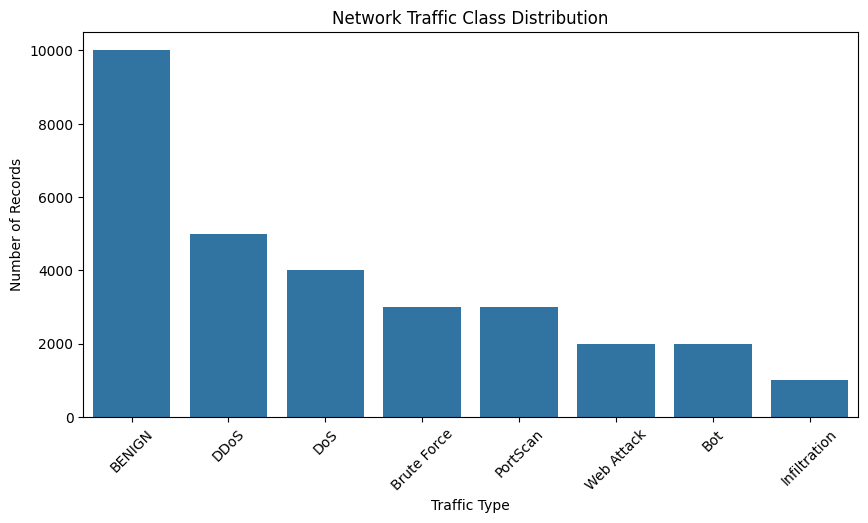

In [29]:
#Attack distribution Visualization

# ============================================
# 12. CLASS DISTRIBUTION
# ============================================

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Label",
    order=df["Label"].value_counts().index
)

plt.xticks(rotation=45)
plt.title("Network Traffic Class Distribution")
plt.xlabel("Traffic Type")
plt.ylabel("Number of Records")
plt.show()

In [30]:
#Binary attack distribution

#We can create a binary target:

#BENIGN → BENIGN
#Everything else → ATTACK

# ============================================
# 13. CREATE BINARY TARGET
# ============================================

df["Attack"] = np.where(
    df["Label"] == "BENIGN",
    "BENIGN",
    "ATTACK"
)

print(df["Attack"].value_counts())

Attack
ATTACK    20000
BENIGN    10000
Name: count, dtype: int64


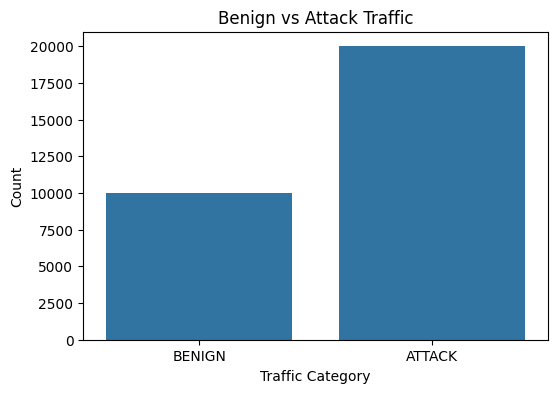

In [31]:
# ============================================
# 14. BINARY CLASS DISTRIBUTION
# ============================================

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Attack")

plt.title("Benign vs Attack Traffic")
plt.xlabel("Traffic Category")
plt.ylabel("Count")
plt.show()

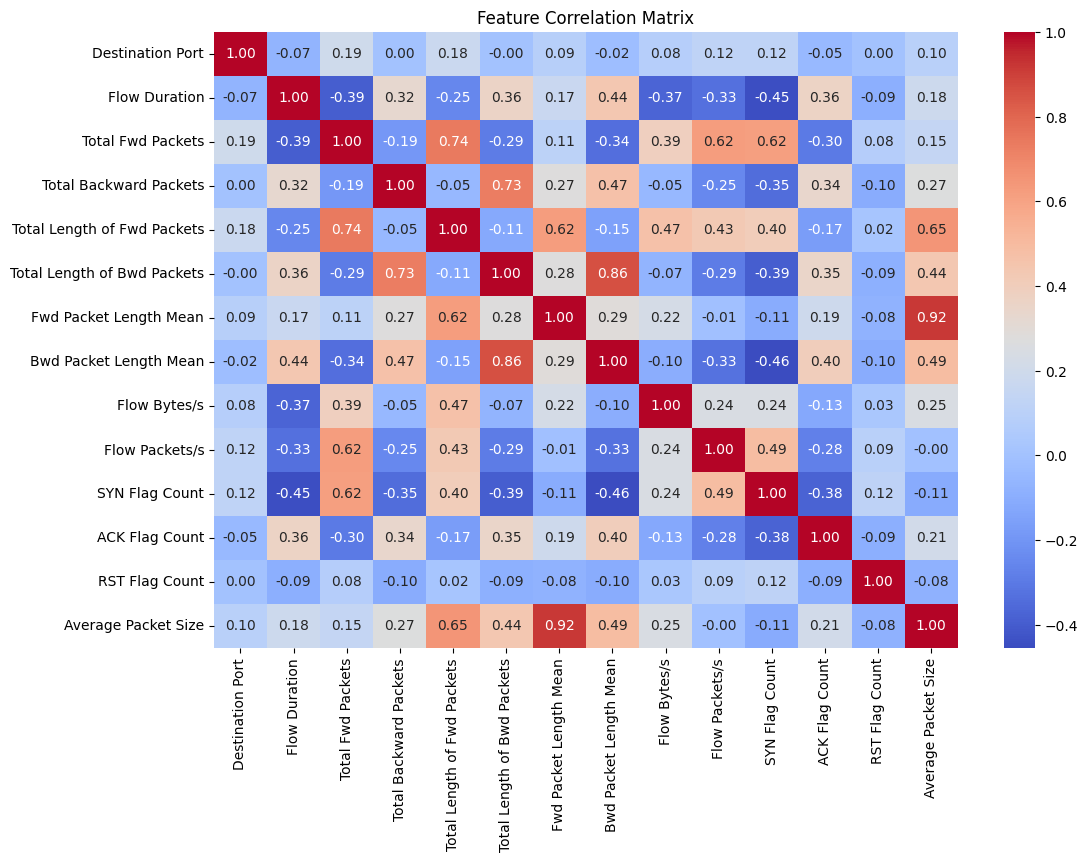

In [32]:
#Correlation analysis

#We can examine relationships between numerical features.

# ============================================
# 15. CORRELATION MATRIX
# ============================================

# Select numerical features only
correlation = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Matrix")
plt.show()

#This helps identify highly correlated features.

In [33]:
#Feature understanding

#Our features represent network-flow characteristics.

"""
Destination Port

The network destination port.

For example:

80    → HTTP
443   → HTTPS
22    → SSH
21    → FTP
Flow Duration

How long the network flow lasted.

Total Fwd Packets

Number of packets moving forward.

Total Backward Packets

Number of packets moving backward.

Flow Bytes/s

Average bytes transferred per second.

Flow Packets/s

Average packets transferred per second.

SYN Flag Count

Number of SYN TCP flags.

ACK Flag Count

Number of ACK TCP flags.

RST Flag Count

Number of reset TCP flags.

Average Packet Size

Average size of packets in the flow.

These features allow ML to learn traffic behavior patterns.

"""

'\nDestination Port\n\nThe network destination port.\n\nFor example:\n\n80    → HTTP\n443   → HTTPS\n22    → SSH\n21    → FTP\nFlow Duration\n\nHow long the network flow lasted.\n\nTotal Fwd Packets\n\nNumber of packets moving forward.\n\nTotal Backward Packets\n\nNumber of packets moving backward.\n\nFlow Bytes/s\n\nAverage bytes transferred per second.\n\nFlow Packets/s\n\nAverage packets transferred per second.\n\nSYN Flag Count\n\nNumber of SYN TCP flags.\n\nACK Flag Count\n\nNumber of ACK TCP flags.\n\nRST Flag Count\n\nNumber of reset TCP flags.\n\nAverage Packet Size\n\nAverage size of packets in the flow.\n\nThese features allow ML to learn traffic behavior patterns.\n\n'

In [34]:
#Feature selection

#We don't want the model to receive the target itself.

#Our target is:

#Label

#So Label must not be an input feature.

#Also:

#Attack

#is derived from Label, so it must also be excluded from the feature set.

In [35]:
# ============================================
# 16. FEATURE SELECTION
# ============================================

# Features used by the ML model
feature_columns = [
    "Destination Port",
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Total Length of Bwd Packets",
    "Fwd Packet Length Mean",
    "Bwd Packet Length Mean",
    "Flow Bytes/s",
    "Flow Packets/s",
    "SYN Flag Count",
    "ACK Flag Count",
    "RST Flag Count",
    "Average Packet Size"
]

X = df[feature_columns]

print("Number of features:", X.shape[1])
print("\nSelected features:")
print(feature_columns)

Number of features: 14

Selected features:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Mean', 'Bwd Packet Length Mean', 'Flow Bytes/s', 'Flow Packets/s', 'SYN Flag Count', 'ACK Flag Count', 'RST Flag Count', 'Average Packet Size']


In [36]:
#Binary classification target

#First we'll solve:

#Is this traffic benign or an attack?

# ============================================
# 17. BINARY TARGET
# ============================================

y_binary = df["Attack"]

print(y_binary.value_counts())

Attack
ATTACK    20000
BENIGN    10000
Name: count, dtype: int64


In [37]:
#Multiclass target

#Then we'll solve:

#What type of attack is this?

# ============================================
# 18. MULTICLASS TARGET
# ============================================

y_multi = df["Label"]

print(y_multi.value_counts())

Label
BENIGN          10000
DDoS             5000
DoS              4000
Brute Force      3000
PortScan         3000
Web Attack       2000
Bot              2000
Infiltration     1000
Name: count, dtype: int64


In [38]:
"""
Train-test split

This is extremely important.

We don't train the model on the entire dataset.

We divide the data:

80% → Training
20% → Testing

Training data teaches the model.

Testing data checks whether the model can handle unseen data. 

"""

"\nTrain-test split\n\nThis is extremely important.\n\nWe don't train the model on the entire dataset.\n\nWe divide the data:\n\n80% → Training\n20% → Testing\n\nTraining data teaches the model.\n\nTesting data checks whether the model can handle unseen data. \n\n"

In [39]:
# ============================================
# 19. BINARY TRAIN-TEST SPLIT
# ============================================

X_train_bin, X_test_bin, y_train_bin, y_test_bin = train_test_split(
    X,
    y_binary,
    test_size=0.20,
    random_state=42,
    stratify=y_binary
)

print("Training data:", X_train_bin.shape)
print("Testing data:", X_test_bin.shape)

#stratify helps preserve the class distribution.

Training data: (24000, 14)
Testing data: (6000, 14)


In [40]:
# ============================================
# 20. MULTICLASS TRAIN-TEST SPLIT
# ============================================

X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X,
    y_multi,
    test_size=0.20,
    random_state=42,
    stratify=y_multi
)

print("Training data:", X_train_multi.shape)
print("Testing data:", X_test_multi.shape)

Training data: (24000, 14)
Testing data: (6000, 14)


In [41]:
"""
Feature scaling

Some models are affected by feature magnitude.

For example:

Flow Duration       → thousands
SYN Flag Count      → 0, 1, 2...
Destination Port    → hundreds

KNN and Logistic Regression benefit from scaling.
                                                """

'\nFeature scaling\n\nSome models are affected by feature magnitude.\n\nFor example:\n\nFlow Duration       → thousands\nSYN Flag Count      → 0, 1, 2...\nDestination Port    → hundreds\n\nKNN and Logistic Regression benefit from scaling.\n                                                '

In [42]:
# ============================================
# 21. FEATURE SCALING
# ============================================

scaler_binary = StandardScaler()

X_train_bin_scaled = scaler_binary.fit_transform(X_train_bin)
X_test_bin_scaled = scaler_binary.transform(X_test_bin)

print("Binary features scaled.")

Binary features scaled.


In [43]:
"""
Notice:

fit_transform()

is used only on training data.

For test data:

transform()

This prevents information leakage. 
                                   """

'\nNotice:\n\nfit_transform()\n\nis used only on training data.\n\nFor test data:\n\ntransform()\n\nThis prevents information leakage. \n                                   '

In [44]:
"""
Model selection

We will compare four algorithms:

1. Logistic Regression

Good baseline classification model.

2. KNN

Classifies based on nearby/similar observations.

3. Decision Tree

Makes decisions using feature-based rules.

4. Random Forest

Uses many decision trees and combines their results.

This gives us a meaningful model comparison.
                                          """

'\nModel selection\n\nWe will compare four algorithms:\n\n1. Logistic Regression\n\nGood baseline classification model.\n\n2. KNN\n\nClassifies based on nearby/similar observations.\n\n3. Decision Tree\n\nMakes decisions using feature-based rules.\n\n4. Random Forest\n\nUses many decision trees and combines their results.\n\nThis gives us a meaningful model comparison.\n                                          '

In [45]:
# ============================================
# 22. LOGISTIC REGRESSION
# ============================================

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_bin_scaled,
    y_train_bin
)

logistic_pred = logistic_model.predict(
    X_test_bin_scaled
)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test_bin, logistic_pred))

Logistic Regression Accuracy: 0.9233333333333333


In [59]:
# ============================================
# 23. K-NEAREST NEIGHBORS
# ============================================

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(
    X_train_bin_scaled,
    y_train_bin
)

knn_pred = knn_model.predict(
    X_test_bin_scaled
)

print("KNN Accuracy:",
      accuracy_score(y_test_bin, knn_pred))

KNN Accuracy: 0.912


In [47]:
# ============================================
# 25. RANDOM FOREST
# ============================================

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_bin,
    y_train_bin
)

rf_pred = rf_model.predict(
    X_test_bin
)

print("Random Forest Accuracy:",
      accuracy_score(y_test_bin, rf_pred))

Random Forest Accuracy: 0.9528333333333333


In [48]:
# ============================================
# 24. DECISION TREE
# ============================================

tree_model = DecisionTreeClassifier(
    random_state=42
)

tree_model.fit(
    X_train_bin,
    y_train_bin
)

tree_pred = tree_model.predict(
    X_test_bin
)

print("Decision Tree Accuracy:",
      accuracy_score(y_test_bin, tree_pred))

Decision Tree Accuracy: 0.9253333333333333


In [49]:
# ============================================
# 26. MODEL COMPARISON
# ============================================

binary_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test_bin, logistic_pred),
        accuracy_score(y_test_bin, knn_pred),
        accuracy_score(y_test_bin, tree_pred),
        accuracy_score(y_test_bin, rf_pred)
    ]
})

binary_results.sort_values(
    by="Accuracy",
    ascending=False
)

,Model,Accuracy
3,Random Forest,0.952833
2,Decision Tree,0.925333
0,Logistic Regression,0.923333
1,KNN,0.912000


In [50]:
#Do not decide the final model based only on accuracy.

#For intrusion detection, missing an attack can be more serious than incorrectly flagging some normal traffic.

In [51]:
#Therefore we also look at:

#Precision
#Recall
#F1-score
#Confusion Matrix

In [52]:
# ============================================
# 27. RANDOM FOREST EVALUATION
# ============================================

print(classification_report(
    y_test_bin,
    rf_pred
))

              precision    recall  f1-score   support

      ATTACK       0.97      0.96      0.96      4000
      BENIGN       0.92      0.94      0.93      2000

    accuracy                           0.95      6000
   macro avg       0.95      0.95      0.95      6000
weighted avg       0.95      0.95      0.95      6000



In [53]:
"""
Precision:

When the model says ATTACK, how often is it actually an attack?

Recall:

Out of all actual attacks, how many did the model detect?

F1-score:

Balance between precision and recall.

For intrusion detection, recall is particularly important because a false negative means an attack was missed.
                                                                                                               """

'\nPrecision:\n\nWhen the model says ATTACK, how often is it actually an attack?\n\nRecall:\n\nOut of all actual attacks, how many did the model detect?\n\nF1-score:\n\nBalance between precision and recall.\n\nFor intrusion detection, recall is particularly important because a false negative means an attack was missed.\n                                                                                                               '

In [54]:
# ============================================
# 27. DECISION TREE EVALUATION
# ============================================

print(classification_report(
    y_test_bin,
    tree_pred
))

              precision    recall  f1-score   support

      ATTACK       0.94      0.94      0.94      4000
      BENIGN       0.89      0.89      0.89      2000

    accuracy                           0.93      6000
   macro avg       0.92      0.92      0.92      6000
weighted avg       0.93      0.93      0.93      6000



In [61]:
# ============================================
# 27. K-NEAREST NEIGHBORS EVALUATION
# ============================================

print(classification_report(
    y_test_bin,
    knn_pred
))

              precision    recall  f1-score   support

      ATTACK       0.95      0.92      0.93      4000
      BENIGN       0.85      0.90      0.87      2000

    accuracy                           0.91      6000
   macro avg       0.90      0.91      0.90      6000
weighted avg       0.91      0.91      0.91      6000



In [62]:
# ============================================
# 27. Logistic Regression EVALUATION
# ============================================

print(classification_report(
    y_test_bin,
    logistic_pred
))

              precision    recall  f1-score   support

      ATTACK       0.95      0.94      0.94      4000
      BENIGN       0.88      0.89      0.89      2000

    accuracy                           0.92      6000
   macro avg       0.91      0.92      0.91      6000
weighted avg       0.92      0.92      0.92      6000



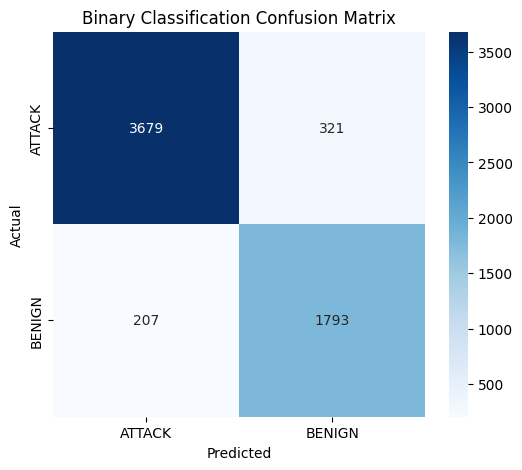

In [63]:
# ============================================
# 28. CONFUSION MATRIX
# ============================================

cm = confusion_matrix(
    y_test_bin,
    knn_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["ATTACK", "BENIGN"],
    yticklabels=["ATTACK", "BENIGN"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Binary Classification Confusion Matrix")

plt.show()

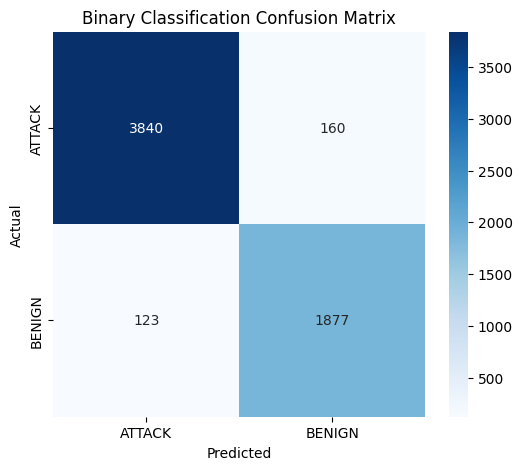

In [64]:
# ============================================
# 28. CONFUSION MATRIX
# ============================================

cm = confusion_matrix(
    y_test_bin,
    rf_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["ATTACK", "BENIGN"],
    yticklabels=["ATTACK", "BENIGN"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Binary Classification Confusion Matrix")

plt.show()

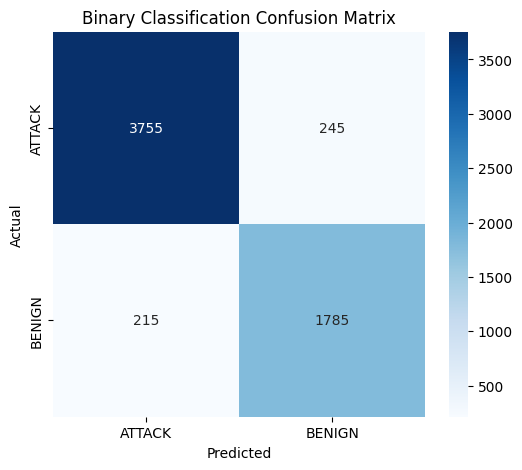

In [65]:
# ============================================
# 28. CONFUSION MATRIX
# ============================================

cm = confusion_matrix(
    y_test_bin,
    logistic_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["ATTACK", "BENIGN"],
    yticklabels=["ATTACK", "BENIGN"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Binary Classification Confusion Matrix")

plt.show()

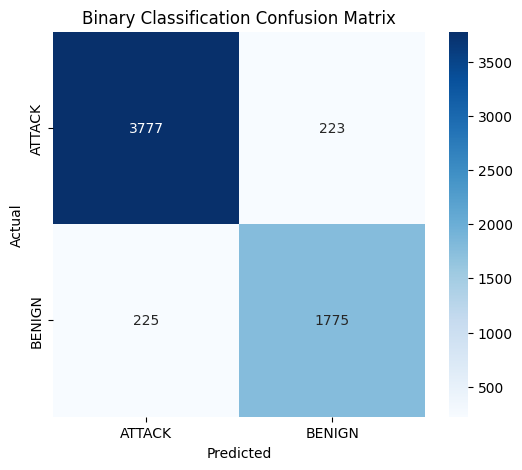

In [67]:
# ============================================
# 28. CONFUSION MATRIX
# ============================================

cm = confusion_matrix(
    y_test_bin,
    tree_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["ATTACK", "BENIGN"],
    yticklabels=["ATTACK", "BENIGN"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Binary Classification Confusion Matrix")

plt.show()

In [68]:
"""
The confusion matrix shows:

Actual vs Predicted

For example:

Actual ATTACK → Predicted BENIGN

is a false negative.

That's an important error in an intrusion detection system. """

"\nThe confusion matrix shows:\n\nActual vs Predicted\n\nFor example:\n\nActual ATTACK → Predicted BENIGN\n\nis a false negative.\n\nThat's an important error in an intrusion detection system. "

In [69]:
"""
Multiclass classification

Now we make the project more interesting.

Instead of:

BENIGN / ATTACK

we ask:

What type of traffic is this?

Classes:

BENIGN
DDoS
DoS
PortScan
Brute Force
Web Attack
Bot
Infiltration 
            """

'\nMulticlass classification\n\nNow we make the project more interesting.\n\nInstead of:\n\nBENIGN / ATTACK\n\nwe ask:\n\nWhat type of traffic is this?\n\nClasses:\n\nBENIGN\nDDoS\nDoS\nPortScan\nBrute Force\nWeb Attack\nBot\nInfiltration \n            '

In [70]:
# ============================================
# 29. MULTICLASS FEATURE SCALING
# ============================================

scaler_multi = StandardScaler()

X_train_multi_scaled = scaler_multi.fit_transform(
    X_train_multi
)

X_test_multi_scaled = scaler_multi.transform(
    X_test_multi
)

In [71]:
# ============================================
# 30. MULTICLASS LOGISTIC REGRESSION
# ============================================

multi_logistic = LogisticRegression(
    max_iter=2000,
    random_state=42
)

multi_logistic.fit(
    X_train_multi_scaled,
    y_train_multi
)

multi_logistic_pred = multi_logistic.predict(
    X_test_multi_scaled
)

print(classification_report(
    y_test_multi,
    multi_logistic_pred
))

              precision    recall  f1-score   support

      BENIGN       0.88      0.93      0.90      2000
         Bot       0.73      0.73      0.73       400
 Brute Force       0.69      0.62      0.65       600
        DDoS       0.93      0.93      0.93      1000
         DoS       0.86      0.86      0.86       800
Infiltration       0.66      0.51      0.57       200
    PortScan       1.00      1.00      1.00       600
  Web Attack       0.76      0.73      0.74       400

    accuracy                           0.85      6000
   macro avg       0.81      0.79      0.80      6000
weighted avg       0.85      0.85      0.85      6000



In [72]:
# ============================================
# 31. MULTICLASS KNN
# ============================================

multi_knn = KNeighborsClassifier(
    n_neighbors=5
)

multi_knn.fit(
    X_train_multi_scaled,
    y_train_multi
)

multi_knn_pred = multi_knn.predict(
    X_test_multi_scaled
)

print(classification_report(
    y_test_multi,
    multi_knn_pred
))

              precision    recall  f1-score   support

      BENIGN       0.83      0.92      0.87      2000
         Bot       0.66      0.67      0.66       400
 Brute Force       0.66      0.62      0.64       600
        DDoS       0.88      0.91      0.89      1000
         DoS       0.80      0.77      0.78       800
Infiltration       0.60      0.25      0.35       200
    PortScan       1.00      1.00      1.00       600
  Web Attack       0.78      0.61      0.68       400

    accuracy                           0.82      6000
   macro avg       0.78      0.72      0.74      6000
weighted avg       0.81      0.82      0.81      6000



In [73]:
# ============================================
# 32. MULTICLASS DECISION TREE
# ============================================

multi_tree = DecisionTreeClassifier(
    random_state=42
)

multi_tree.fit(
    X_train_multi,
    y_train_multi
)

multi_tree_pred = multi_tree.predict(
    X_test_multi
)

print(classification_report(
    y_test_multi,
    multi_tree_pred
))

              precision    recall  f1-score   support

      BENIGN       0.89      0.90      0.89      2000
         Bot       0.71      0.71      0.71       400
 Brute Force       0.83      0.78      0.80       600
        DDoS       0.90      0.88      0.89      1000
         DoS       0.78      0.79      0.79       800
Infiltration       0.46      0.48      0.47       200
    PortScan       0.99      0.99      0.99       600
  Web Attack       0.63      0.65      0.64       400

    accuracy                           0.84      6000
   macro avg       0.77      0.77      0.77      6000
weighted avg       0.84      0.84      0.84      6000



In [74]:
# ============================================
# 33. MULTICLASS RANDOM FOREST
# ============================================

multi_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

multi_rf.fit(
    X_train_multi,
    y_train_multi
)

multi_rf_pred = multi_rf.predict(
    X_test_multi
)

print(classification_report(
    y_test_multi,
    multi_rf_pred
))

              precision    recall  f1-score   support

      BENIGN       0.90      0.96      0.93      2000
         Bot       0.77      0.82      0.80       400
 Brute Force       0.92      0.78      0.85       600
        DDoS       0.93      0.92      0.93      1000
         DoS       0.85      0.86      0.86       800
Infiltration       0.64      0.48      0.55       200
    PortScan       1.00      1.00      1.00       600
  Web Attack       0.77      0.71      0.74       400

    accuracy                           0.89      6000
   macro avg       0.85      0.82      0.83      6000
weighted avg       0.88      0.89      0.88      6000



In [75]:
# ============================================
# 34. MULTICLASS MODEL COMPARISON
# ============================================

multi_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_score(y_test_multi, multi_logistic_pred),
        accuracy_score(y_test_multi, multi_knn_pred),
        accuracy_score(y_test_multi, multi_tree_pred),
        accuracy_score(y_test_multi, multi_rf_pred)
    ],

    "Precision": [
        precision_score(
            y_test_multi,
            multi_logistic_pred,
            average="weighted",
            zero_division=0
        ),
        precision_score(
            y_test_multi,
            multi_knn_pred,
            average="weighted",
            zero_division=0
        ),
        precision_score(
            y_test_multi,
            multi_tree_pred,
            average="weighted",
            zero_division=0
        ),
        precision_score(
            y_test_multi,
            multi_rf_pred,
            average="weighted",
            zero_division=0
        )
    ],

    "Recall": [
        recall_score(
            y_test_multi,
            multi_logistic_pred,
            average="weighted",
            zero_division=0
        ),
        recall_score(
            y_test_multi,
            multi_knn_pred,
            average="weighted",
            zero_division=0
        ),
        recall_score(
            y_test_multi,
            multi_tree_pred,
            average="weighted",
            zero_division=0
        ),
        recall_score(
            y_test_multi,
            multi_rf_pred,
            average="weighted",
            zero_division=0
        )
    ],

    "F1": [
        f1_score(
            y_test_multi,
            multi_logistic_pred,
            average="weighted",
            zero_division=0
        ),
        f1_score(
            y_test_multi,
            multi_knn_pred,
            average="weighted",
            zero_division=0
        ),
        f1_score(
            y_test_multi,
            multi_tree_pred,
            average="weighted",
            zero_division=0
        ),
        f1_score(
            y_test_multi,
            multi_rf_pred,
            average="weighted",
            zero_division=0
        )
    ]
})

multi_results

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.855000,0.851145,0.855000,0.852283
1,KNN,0.816833,0.810493,0.816833,0.809526
2,Decision Tree,0.835333,0.836786,0.835333,0.835912
3,Random Forest,0.886500,0.884527,0.886500,0.884089


In [76]:
"""
Hyperparameter tuning

Now we improve the selected model.

Suppose Random Forest performs well in our actual evaluation.

We shouldn't simply say:

"Random Forest is best."

We can tune it.

Important distinction:

Model selection:

Which algorithm should we use?

Hyperparameter tuning:

What settings should that algorithm use?
                                          """

'\nHyperparameter tuning\n\nNow we improve the selected model.\n\nSuppose Random Forest performs well in our actual evaluation.\n\nWe shouldn\'t simply say:\n\n"Random Forest is best."\n\nWe can tune it.\n\nImportant distinction:\n\nModel selection:\n\nWhich algorithm should we use?\n\nHyperparameter tuning:\n\nWhat settings should that algorithm use?\n                                          '

In [77]:
"""
Random Forest tuning

Important hyperparameters include:

n_estimators
max_depth
min_samples_split
min_samples_leaf 
                    """

'\nRandom Forest tuning\n\nImportant hyperparameters include:\n\nn_estimators\nmax_depth\nmin_samples_split\nmin_samples_leaf \n                    '

In [ ]:
# ============================================
# 35. RANDOM FOREST HYPERPARAMETER TUNING
# ============================================

param_grid = {
    "n_estimators": [100, 150],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),

    param_grid=param_grid,

    cv=3,

    scoring="f1_weighted",

    n_jobs=-1,

    verbose=1
)

grid_search.fit(
    X_train_multi,
    y_train_multi
)

In [81]:
# ============================================
# 36. BEST HYPERPARAMETERS
# ============================================

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Score:")
print(grid_search.best_score_)

#The computer will determine the actual best combination.

Best Parameters:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}

Best Cross-Validation Score:
0.8845621104210366


In [ ]:
# Alert Generation
from datetime import datetime

def generate_alert(source_ip, attack_type):
    alert = {
        "timestamp": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "source_ip": source_ip,
        "attack_type": attack_type,
        "severity": "HIGH",
        "status": "Attack Detected"
    }

    print("🚨 INTRUSION ALERT 🚨")
    print(f"Time: {alert['timestamp']}")
    print(f"Source IP: {alert['source_ip']}")
    print(f"Attack Type: {alert['attack_type']}")
    print(f"Severity: {alert['severity']}")

    return alert
